In [12]:
##### BVerfG
##### Referee: Prepare for / from GPT
##### 240129

##### HOUSEKEEPING ----
##### clean
import os
import glob
import pandas as pd
import numpy as np
import re
from nltk.tokenize import word_tokenize
import matplotlib.pyplot as plt
import seaborn as sns

##### set working directory
os.chdir("/Users/amao/git/Constitutional_NLP_Summer_2022/2024 Referee")

##### EXTRACT DOMAIN FROM GPT RESPONSE ----
#### extract information from GPT ----
### extract domain number from GPT response ----
### prepare files
directory = '/Users/amao/git/Constitutional_NLP_Summer_2022/venv/senate_1/responses'
write_path = '/Users/amao/git/Constitutional_NLP_Summer_2022/venv/senate_1/bverfg.csv'

##### load prepared data
# bverfg = pd.read_pickle("bverfg240129.pkl")


In [16]:
# !conda install -y nltk matplotlib seaborn

import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to /Users/amao/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [14]:
root = '/Users/amao/git/Constitutional_NLP_Summer_2022'
# df_cleaned_final = pd.read_csv('data/df_cleaned_final_new.csv', index_col=[0])
# df_cleaned = pd.read_csv(os.path.join(root, 'data', 'court_case_data.csv')).drop_duplicates(subset=['uid']) # already filtered to 1 domain?
# print(df_cleaned.shape)
bverfg = pd.read_csv(os.path.join(root, 'venv', 'senate_1', 'bverfg_senate_1.csv'))
bverfg

/var/folders/b_/djy58vhd1s3d4l09hngvbng40000gp/T/ipykernel_29911/1355772930.py:5: DtypeWarning: Columns (84,85,91,1425) have mixed types. Specify dtype option on import or set low_memory=False.
  bverfg = pd.read_csv(os.path.join(root, 'venv', 'senate_1', 'bverfg_senate_1.csv'))


,Unnamed: 0,id,date_and_first_docket,az,senate_and_chamber,judges,short_description,decision,full_text,url,...,ref2_langenfeld,ref2_wallrabenstein,sumref2,sumdm2,sumcomp2,tokens,nrow,dm,name,sumref_new
0,1,1,30. Dezember 1997 - 1 BvR 2264/97,'1 BvR 2264/97',1. Senat,"['seidl', 'haas', 'hoemig']",Bundesverfassungsgericht - Entscheidungen - ...,NaN,Bundesverfassungsgericht \n- 1 BvR 2264/97 -\n...,https://www.bundesverfassungsgericht.de/Shared...,...,0,0,0,0,0,1665,NaN,NaN,NaN,0
1,2,2,30. Dezember 1997 - 1 BvR 2339/95,"'1 BvR 2339/95 1 BvR 5/97', ''",1. Senat 1. Kammer,"['seidl', 'haas', 'hoemig']",Bundesverfassungsgericht - Entscheidungen - ...,NaN,Bundesverfassungsgericht \n- 1 BvR 2339/95 - \...,https://www.bundesverfassungsgericht.de/Shared...,...,0,0,0,0,0,3020,NaN,NaN,NaN,0
2,3,3,30. Dezember 1997 - 1 BvR 2368/97,'1 BvR 2368/97',1. Senat,"['seidl', 'haas', 'hoemig']",Bundesverfassungsgericht - Entscheidungen - ...,NaN,Bundesverfassungsgericht \n- 1 BvR 2368/97 -\n...,https://www.bundesverfassungsgericht.de/Shared...,...,0,0,0,0,0,1311,NaN,NaN,NaN,0
3,4,4,05. Januar 1998,'2 BvR 2198/97',2. Senat,"['limbach', 'kruis', 'winter']",Bundesverfassungsgericht - Entscheidungen - ...,Die Verfassungsbeschwerde wird nicht zur\n ...,Bundesverfassungsgericht \n- 2 BvR 2198/97 - \...,https://www.bundesverfassungsgericht.de/Shared...,...,0,0,2,3,9,567,NaN,NaN,NaN,0
4,5,5,08. Januar 1998 - 1 BvR 390/96,'1 BvR 390/96',1. Senat,"['kuehling', 'jaeger', 'steiner']",Bundesverfassungsgericht - Entscheidungen - ...,NaN,Bundesverfassungsgericht \n- 1 BvR 390/96 -\n\...,https://www.bundesverfassungsgericht.de/Shared...,...,0,0,0,0,0,638,NaN,NaN,NaN,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8189,8190,8190,31. Oktober 2022 - 2 BvR 1838/22,'2 BvR 1838/22',2. Senat 1. Kammer,"['koenig', 'pmueller', 'wallrabenstein']",Bundesverfassungsgericht - Entscheidungen - ...,Die Übergabe des Beschwerdeführers an die Behö...,BUNDESVERFASSUNGSGERICHT \n\n\n\n\n\n \n\n\n -...,https://www.bundesverfassungsgericht.de/Shared...,...,0,1,3,3,12,728,NaN,NaN,NaN,0
8190,8191,8191,04. November 2022 - 2 BvR 2202/19,'2 BvR 2202/19',2. Senat 3. Kammer,"['hermanns', 'maidowski', 'langenfeld']",Bundesverfassungsgericht - Entscheidungen - ...,Die Verfassungsbeschwerde wird nicht zur Entsc...,BUNDESVERFASSUNGSGERICHT \n\n\n\n\n\n \n\n\n -...,https://www.bundesverfassungsgericht.de/Shared...,...,1,0,2,2,14,4083,NaN,NaN,NaN,0
8191,8192,8192,10. November 2022 - 1 BvR 1941/22,'1 BvR 1941/22',1. Senat 1. Kammer,"['harbarth', 'ott', 'haertel']",Bundesverfassungsgericht - Entscheidungen - ...,"Es wird festgestellt, dass der Beschluss des L...",BUNDESVERFASSUNGSGERICHT \n\n\n\n\n\n \n\n\n -...,https://www.bundesverfassungsgericht.de/Shared...,...,0,0,0,0,0,3443,NaN,NaN,NaN,2
8192,8193,8193,17. November 2022 - 2 BvR 2013/22,'2 BvR 2013/22',2. Senat 3. Kammer,"['koenig', 'hermanns', 'pmueller']",Bundesverfassungsgericht - Entscheidungen - ...,Die Zwangsvollstreckung aus der vollstreckbare...,BUNDESVERFASSUNGSGERICHT \n\n\n\n\n\n \n\n\n -...,https://www.bundesverfassungsgericht.de/Shared...,...,0,0,2,3,13,764,NaN,NaN,NaN,0


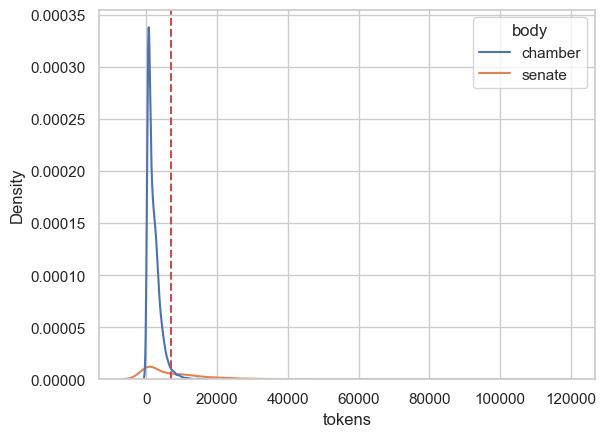

count     8194
unique    4254
top        137
freq        15
Name: tokens, dtype: int64
count     6957
unique    3581
top        653
freq        11
Name: tokens, dtype: int64
877
163
37
      nrow    dm    id
7        8  None    14
14      15  None    51
125    126  None   844
155    156  None  1023
251    252  None  1789
...    ...   ...   ...
1224  1225  None  8176
1225  1226  None  8179
1226  1227  None  8180
1227  1228  None  8185
1228  1229  None  8187

[825 rows x 3 columns]
positive_dm_vars = Index([], dtype='object') gegenstand_number = 2
positive_dm_vars = Index([], dtype='object') gegenstand_number = 3
positive_dm_vars = Index([], dtype='object') gegenstand_number = 5
positive_dm_vars = Index([], dtype='object') gegenstand_number = 5
positive_dm_vars = Index([], dtype='object') gegenstand_number = 2
positive_dm_vars = Index([], dtype='object') gegenstand_number = 2
positive_dm_vars = Index([], dtype='object') gegenstand_number = 1


TypeError: '<=' not supported between instances of 'NoneType' and 'int'

In [17]:

##### PREPARE FOR GPT ----
##### token length ----
# Create a new column to store the number of tokens for each observation
bverfg['tokens'] = None

# Loop through each row of the dataset
for i in range(len(bverfg)):
    # Combine the two text parts
    combined_text = f"{bverfg.loc[i, 'short_description']} {bverfg.loc[i, 'full_text']}"
    
    # Tokenize the combined text
    tokens = word_tokenize(combined_text)
    
    # Count the number of tokens and store in the new column
    bverfg.at[i, 'tokens'] = len(tokens)

# Plotting
sns.set_theme(style="whitegrid")
plot = sns.kdeplot(data=bverfg[(bverfg['body'] != "plenary") & (bverfg['body'] != "complaint")], x='tokens', hue='body')
plot.axvline(x=7000, color='r', linestyle='--')
plt.show()

print(bverfg['tokens'].describe())
print(bverfg[bverfg['body'] == "chamber"]['tokens'].describe())
print(len(bverfg[(bverfg['body'] == "chamber") & (bverfg['tokens'] > 4000)]))
print(len(bverfg[(bverfg['body'] == "chamber") & (bverfg['tokens'] > 7000)]))
print(len(bverfg[(bverfg['body'] == "chamber") & (bverfg['sumref'] > 1) & (bverfg['sumdm'] > 1) & (bverfg['tokens'] > 7000)]))

##### senate 1 chamber ----
  #### select relevant cases ----
mult = bverfg[(bverfg['body'] == "senate")].copy()
mult['nrow'] = range(1, len(mult) + 1)

files = sorted(glob.glob(f"{directory}/*.txt"))
num = range(1, len(mult) + 1)
extract = pd.DataFrame({'nrow': num, 'dm': [None] * len(num)})
extract = extract.merge(mult[['id', 'nrow']], on='nrow', how='left')

### loop over all response files
for i, file in enumerate(files):
    with open(file, 'r') as f:
        content = f.readlines()
        hgegenstand_number = re.search(r"Gegenstand\s*(\d+)", content[-1])
        if hgegenstand_number:
            gegenstand_number = re.search(r"\d", hgegenstand_number.group(0)).group(0)
            extract.loc[extract['nrow'] == i + 1, 'dm'] = int(gegenstand_number)

### check for missing values ----
print(extract[extract['dm'].isna()])

### handle these cases manually
manual_corrections = {
    90: 5,
    99: 2,
    186: 1,
    386: 1,
    892: 1,
    1201: 1,
    1280: 1
}

for key, value in manual_corrections.items():
    extract.loc[extract['nrow'] == key, 'dm'] = value

### retrieve name of relevant domain ----
extract['name'] = None

for i in range(len(mult)):
    case_id = extract.loc[i, 'id']
    positive_dm_vars = bverfg[bverfg['id'] == case_id].filter(regex="^dm_").columns[bverfg.loc[bverfg['id'] == case_id, bverfg.filter(regex="^dm_").columns].values.flatten() != 0]
    gegenstand_number = extract.loc[i, 'dm']
    extract.loc[i, 'name'] = positive_dm_vars[int(gegenstand_number) - 1] if gegenstand_number <= len(positive_dm_vars) else None
    print(f"positive_dm_vars = {positive_dm_vars} gegenstand_number = {gegenstand_number}")

### manual corrections ----
extract.loc[extract['nrow'] == 186, 'name'] = "dm_property"
extract.loc[extract['nrow'] == 463, 'name'] = "dm_freedomgeneral"
extract.loc[extract['nrow'] == 1280, 'name'] = "dm_art"

### merge with main dataset ----
bverfg = bverfg.merge(extract[['id', 'dm', 'name']], on='id', how='left')

print(bverfg)


In [ ]:

### correct one case where domain cannot be defined ----
bverfg.loc[bverfg['id'] == 7266, 'dm_manifestations'] = 0
bverfg.loc[bverfg['id'] == 7266, 'dm_professions'] = 0

### recalculate number of domains per case ----
bverfg['sumdm'] = bverfg.filter(regex="^dm_").sum(axis=1)

### redefine referee ----
conditions = [
    (bverfg['dm_environmental'] == 1) | (bverfg['dm_property'] == 1) | 
    (bverfg['dm_ip'] == 1) | (bverfg['dm_inheritance'] == 1) | 
    (bverfg['dm_childallowance'] == 1) | (bverfg['dm_developmentcharge'] == 1) | 
    (bverfg['dm_landsale'] == 1) & 
    (bverfg['date'] > "1997-12-31") & (bverfg['date'] < "1998-02-28")
]

bverfg['ref_seidl'] = np.where(conditions[0], 1, 0)

conditions = [
    ((bverfg['date'] > "1998-02-27") & (bverfg['date'] < "1999-12-17") & 
    ((bverfg['dm_farming'] == 1) | (bverfg['dm_childallowance'] == 1) | 
    (bverfg['dm_developmentcharge'] == 1) | (bverfg['dm_landsale'] == 1))) | 
    ((bverfg['date'] > "1998-02-27") & (bverfg['date'] < "2010-03-15") & 
    ((bverfg['dm_environmental'] == 1) | (bverfg['dm_property'] == 1) | 
    (bverfg['dm_ip'] == 1) | (bverfg['dm_inheritance'] == 1)))
]

bverfg['ref_papier'] = np.where(conditions[0], 1, 0)

conditions = [
    ((bverfg['date'] > "1997-12-31") & (bverfg['date'] < "1999-12-17") & 
    (bverfg['dm_postwar'] == 1)) | 
    ((bverfg['date'] > "1997-12-31") & (bverfg['date'] < "2006-10-03") & 
    ((bverfg['dm_taking'] == 1) | (bverfg['dm_tax'] == 1) | 
    (bverfg['dm_levies'] == 1) | (bverfg['dm_construction'] == 1) | 
    (bverfg['dm_planning'] == 1) | (bverfg['dm_landuse'] == 1) | 
    (bverfg['dm_conservation'] == 1) | (bverfg['dm_landconsolidation'] == 1))) | 
    ((bverfg['date'] > "1999-12-16") & (bverfg['date'] < "2006-10-03") & 
    ((bverfg['dm_landsale'] == 1) | (bverfg['dm_developmentcharge'] == 1)))
]

bverfg['ref_haas'] = np.where(conditions[0], 1, 0)

# conditions = [
#     ((bverfg['date'] > "1997-12-31") & (bverfg['date'] < "1999-12-17") & 
#     ((bverfg['dm_association'] == 1) | (bverfg['dm_petitions
